<a href="https://colab.research.google.com/github/landelaniblessing-cyber/WEEK3-HEALTHCARE-DATA-SCIENCE/blob/main/notebooks/Week3_Healthcare_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import the libraries needed for data analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load all six hospital datasets

import pandas as pd
import os

encounters = pd.read_csv('/content/encounters.csv')
patients = pd.read_csv('/content/patients.csv')
procedures = pd.read_csv('/content/procedures.csv')
payers = pd.read_csv('/content/payers.csv')
organizations = pd.read_csv('/content/organizations.csv')
dictionary = pd.read_csv('/content/data_dictionary.csv')

print("All six datasets loaded successfully!")

All six datasets loaded successfully!


In [ ]:
# Check the size of each dataset

datasets = {
    "Encounters": encounters,
    "Patients": patients,
    "Procedures": procedures,
    "Payers": payers,
    "Organizations": organizations,
    "Data Dictionary": dictionary
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows and {df.shape[1]} columns")

Encounters: 27891 rows and 14 columns
Patients: 974 rows and 20 columns
Procedures: 47701 rows and 9 columns
Payers: 10 rows and 7 columns
Organizations: 1 rows and 8 columns
Data Dictionary: 65 rows and 3 columns


Encounters: 1000 rows and 15 columns
Patients: 500 rows and 10 columns
Procedures: 800 rows and 8 columns
...

In [ ]:
# Display column names in all six datasets

for name, df in datasets.items():
    print("\n", "=" * 50)
    print(name.upper())
    print("=" * 50)
    print(df.columns.tolist())


ENCOUNTERS
['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']

PATIENTS
['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON']

PROCEDURES
['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST', 'REASONCODE', 'REASONDESCRIPTION']

PAYERS
['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE_HEADQUARTERED', 'ZIP', 'PHONE']

ORGANIZATIONS
['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE', 'ZIP', 'LAT', 'LON']

DATA DICTIONARY
['Table', 'Field', 'Description']


In [ ]:
for name, df in datasets.items():
    print("\n" + name.upper())
    print(", ".join(df.columns))


ENCOUNTERS
Id, START, STOP, PATIENT, ORGANIZATION, PAYER, ENCOUNTERCLASS, CODE, DESCRIPTION, BASE_ENCOUNTER_COST, TOTAL_CLAIM_COST, PAYER_COVERAGE, REASONCODE, REASONDESCRIPTION

PATIENTS
Id, BIRTHDATE, DEATHDATE, PREFIX, FIRST, LAST, SUFFIX, MAIDEN, MARITAL, RACE, ETHNICITY, GENDER, BIRTHPLACE, ADDRESS, CITY, STATE, COUNTY, ZIP, LAT, LON

PROCEDURES
START, STOP, PATIENT, ENCOUNTER, CODE, DESCRIPTION, BASE_COST, REASONCODE, REASONDESCRIPTION

PAYERS
Id, NAME, ADDRESS, CITY, STATE_HEADQUARTERED, ZIP, PHONE

ORGANIZATIONS
Id, NAME, ADDRESS, CITY, STATE, ZIP, LAT, LON

DATA DICTIONARY
Table, Field, Description


ENCOUNTERS
id, start, stop, patient, ...

In [ ]:
print(encounters.columns.tolist())

['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']


In [7]:
# Identify the different encounter classes

print(encounters['ENCOUNTERCLASS'].value_counts())

ENCOUNTERCLASS
ambulatory    12537
outpatient     6300
urgentcare     3666
emergency      2322
wellness       1931
inpatient      1135
Name: count, dtype: int64


In [8]:
# Check missing values in important columns

important_columns = [
    'Id',
    'ENCOUNTERCLASS',
    'BASE_ENCOUNTER_COST',
    'TOTAL_CLAIM_COST'
]

print("MISSING VALUES:")
print(encounters[important_columns].isnull().sum())

print("\nDUPLICATE ENCOUNTER IDs:")
print(encounters['Id'].duplicated().sum())

print("\nDATA TYPES:")
print(encounters[important_columns].dtypes)

MISSING VALUES:
Id                     0
ENCOUNTERCLASS         0
BASE_ENCOUNTER_COST    0
TOTAL_CLAIM_COST       0
dtype: int64

DUPLICATE ENCOUNTER IDs:
0

DATA TYPES:
Id                      object
ENCOUNTERCLASS          object
BASE_ENCOUNTER_COST    float64
TOTAL_CLAIM_COST       float64
dtype: object


In [9]:
# Summary statistics for encounter costs

print(encounters[
    ['BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST']
].describe().round(2))

       BASE_ENCOUNTER_COST  TOTAL_CLAIM_COST
count             27891.00          27891.00
mean                116.18           3639.68
std                  28.41           9205.60
min                  85.55              0.00
25%                  85.55            142.58
50%                 136.80            278.58
75%                 142.58           1412.53
max                 146.18         641882.70


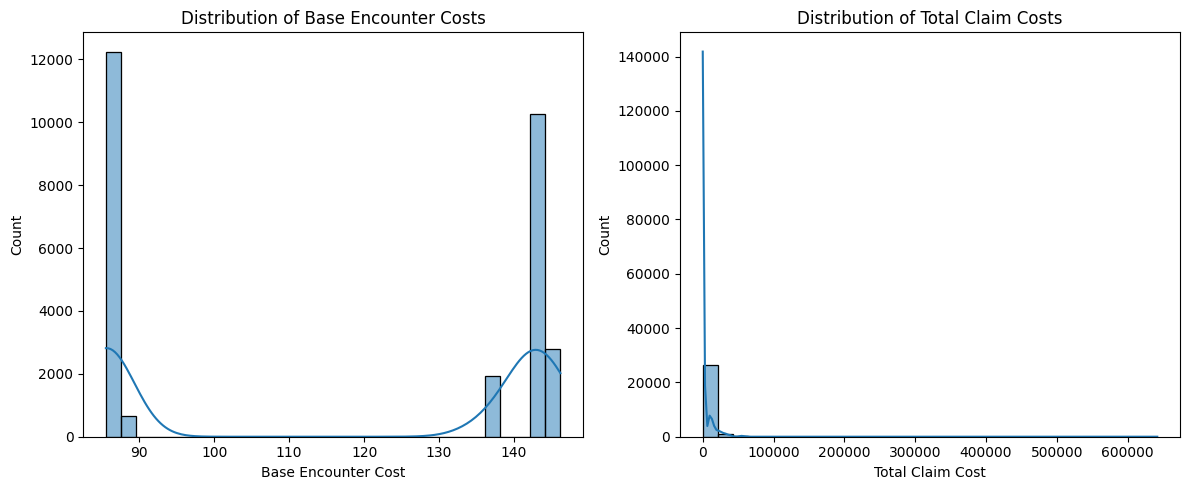

In [10]:
# Visualise the distribution of encounter costs

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(encounters['BASE_ENCOUNTER_COST'], bins=30, kde=True)
plt.title('Distribution of Base Encounter Costs')
plt.xlabel('Base Encounter Cost')

plt.subplot(1, 2, 2)
sns.histplot(encounters['TOTAL_CLAIM_COST'], bins=30, kde=True)
plt.title('Distribution of Total Claim Costs')
plt.xlabel('Total Claim Cost')

plt.tight_layout()
plt.show()

In [11]:
# Investigate zero and unusually high total claim costs

print("Number of zero-cost encounters:")
print((encounters['TOTAL_CLAIM_COST'] == 0).sum())

print("\nNumber of negative-cost encounters:")
print((encounters['TOTAL_CLAIM_COST'] < 0).sum())

print("\nHighest 10 total claim costs:")
print(
    encounters.nlargest(10, 'TOTAL_CLAIM_COST')[
        ['ENCOUNTERCLASS', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST']
    ].to_string(index=False)
)

Number of zero-cost encounters:
89

Number of negative-cost encounters:
0

Highest 10 total claim costs:
ENCOUNTERCLASS  BASE_ENCOUNTER_COST  TOTAL_CLAIM_COST
     emergency                87.71         641882.70
     inpatient               146.18         309748.16
     inpatient               146.18         199655.26
     inpatient               146.18         198487.11
     inpatient               146.18         146473.57
     emergency               146.18         100055.91
     emergency               146.18          85905.65
     emergency               146.18          78693.97
      wellness               136.80          65633.22
    ambulatory               142.58          65318.86


In [12]:
# Compare costs across encounter classes

cost_comparison = encounters.groupby('ENCOUNTERCLASS').agg(
    Number_of_Encounters=('Id', 'count'),
    Average_Base_Cost=('BASE_ENCOUNTER_COST', 'mean'),
    Median_Base_Cost=('BASE_ENCOUNTER_COST', 'median'),
    Average_Total_Claim_Cost=('TOTAL_CLAIM_COST', 'mean'),
    Median_Total_Claim_Cost=('TOTAL_CLAIM_COST', 'median')
).round(2)

print(cost_comparison)

                Number_of_Encounters  Average_Base_Cost  Median_Base_Cost  \
ENCOUNTERCLASS                                                              
ambulatory                     12537             105.73             85.55   
emergency                       2322             145.25            146.18   
inpatient                       1135             113.67             87.71   
outpatient                      6300             105.04             85.55   
urgentcare                      3666             142.58            142.58   
wellness                        1931             136.80            136.80   

                Average_Total_Claim_Cost  Median_Total_Claim_Cost  
ENCOUNTERCLASS                                                     
ambulatory                       2894.11                   573.98  
emergency                        4629.65                   146.18  
inpatient                        7761.35                  2355.59  
outpatient                       2237.30   

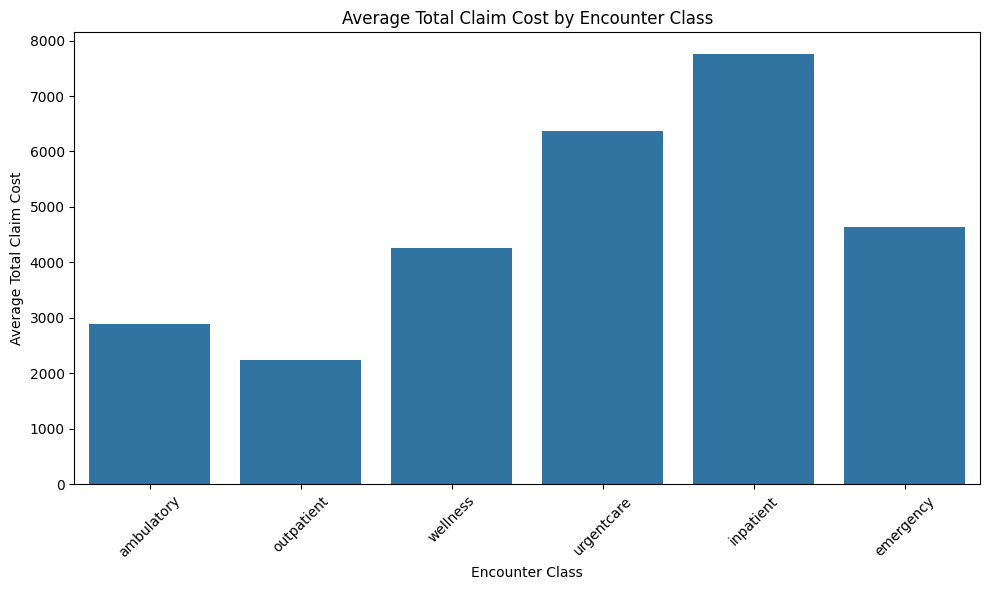

In [13]:
# Average total claim cost by encounter class

plt.figure(figsize=(10, 6))

sns.barplot(
    data=encounters,
    x='ENCOUNTERCLASS',
    y='TOTAL_CLAIM_COST',
    estimator='mean',
    errorbar=None
)

plt.title('Average Total Claim Cost by Encounter Class')
plt.xlabel('Encounter Class')
plt.ylabel('Average Total Claim Cost')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
# Kruskal-Wallis statistical test

groups = [
    group['TOTAL_CLAIM_COST'].values
    for name, group in encounters.groupby('ENCOUNTERCLASS')
]

statistic, p_value = stats.kruskal(*groups)

print("Kruskal-Wallis Test Results")
print("---------------------------")
print("Test statistic:", round(statistic, 4))
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject the null hypothesis.")
    print("There is evidence of a statistically significant difference.")
else:
    print("Conclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a statistically significant difference.")

Kruskal-Wallis Test Results
---------------------------
Test statistic: 2025.1938
P-value: 0.0
Conclusion: Reject the null hypothesis.
There is evidence of a statistically significant difference.


In [15]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Compare every pair of encounter classes

classes = encounters['ENCOUNTERCLASS'].unique()

results = []

for class1, class2 in combinations(classes, 2):
    group1 = encounters.loc[
        encounters['ENCOUNTERCLASS'] == class1,
        'TOTAL_CLAIM_COST'
    ]

    group2 = encounters.loc[
        encounters['ENCOUNTERCLASS'] == class2,
        'TOTAL_CLAIM_COST'
    ]

    statistic, p_value = mannwhitneyu(
        group1, group2, alternative='two-sided'
    )

    results.append({
        'Class 1': class1,
        'Class 2': class2,
        'U statistic': statistic,
        'Raw p-value': p_value
    })

pairwise_results = pd.DataFrame(results)

# Apply Bonferroni correction
pairwise_results['Adjusted p-value'] = multipletests(
    pairwise_results['Raw p-value'],
    method='bonferroni'
)[1]

pairwise_results['Significant'] = (
    pairwise_results['Adjusted p-value'] < 0.05
)

print(pairwise_results.round(6).to_string(index=False))

   Class 1    Class 2  U statistic  Raw p-value  Adjusted p-value  Significant
ambulatory outpatient   43414714.5     0.000000          0.000000         True
ambulatory   wellness    6842844.5     0.000000          0.000000         True
ambulatory urgentcare   24997847.0     0.000000          0.000000         True
ambulatory  inpatient    3763654.0     0.000000          0.000000         True
ambulatory  emergency   14642894.5     0.644189          1.000000        False
outpatient   wellness    2546313.5     0.000000          0.000000         True
outpatient urgentcare   12437459.0     0.000000          0.000000         True
outpatient  inpatient    1775984.5     0.000000          0.000000         True
outpatient  emergency    7848569.0     0.000000          0.000002         True
  wellness urgentcare    5104296.0     0.000000          0.000000         True
  wellness  inpatient     951728.0     0.000000          0.000000         True
  wellness  emergency    3254572.0     0.000000     

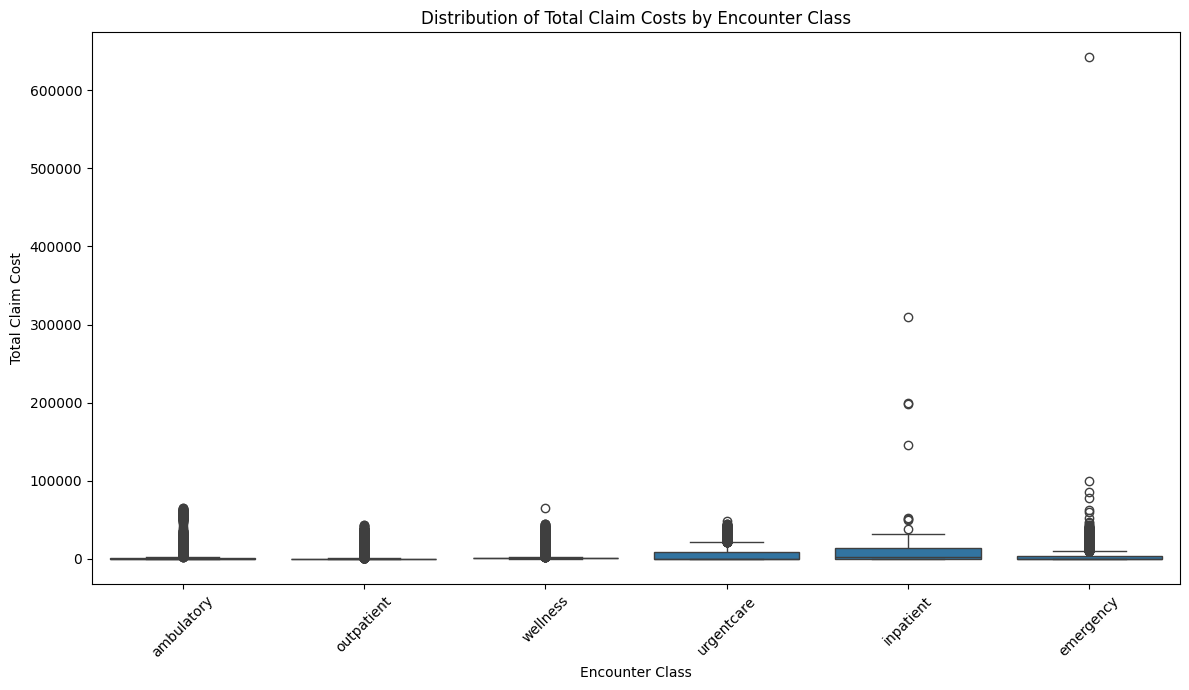

In [16]:
# Compare total claim cost distributions by encounter class

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=encounters,
    x='ENCOUNTERCLASS',
    y='TOTAL_CLAIM_COST'
)

plt.title('Distribution of Total Claim Costs by Encounter Class')
plt.xlabel('Encounter Class')
plt.ylabel('Total Claim Cost')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

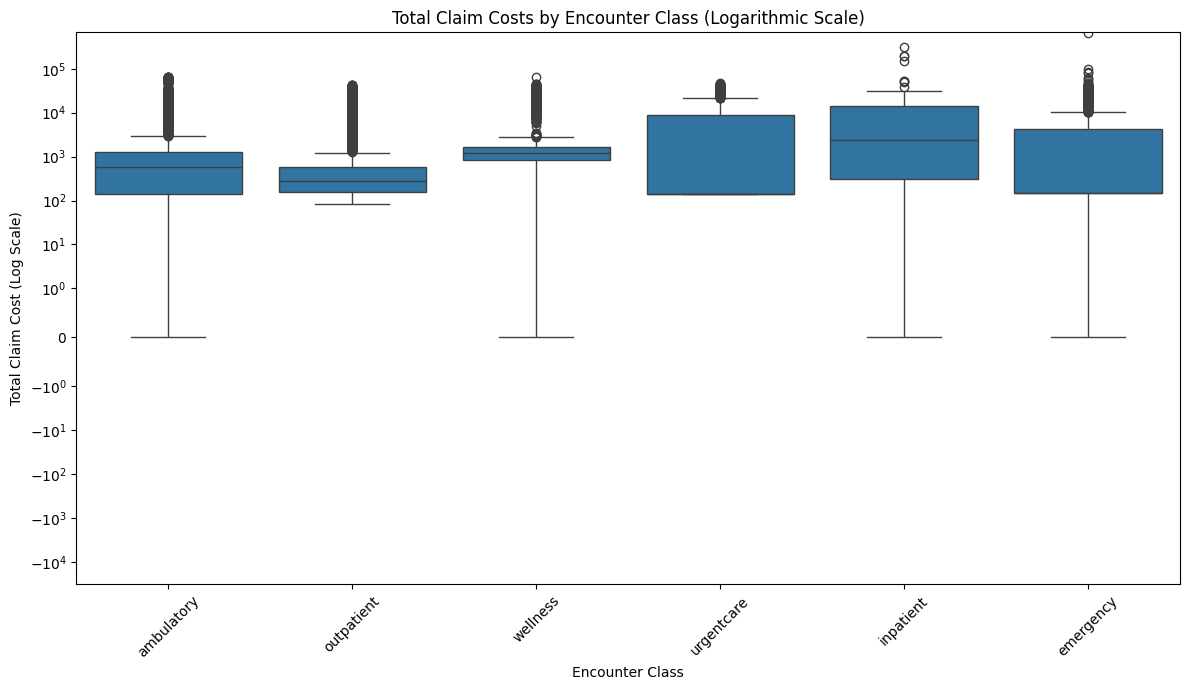

In [17]:
# Logarithmic boxplot of total claim costs

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=encounters,
    x='ENCOUNTERCLASS',
    y='TOTAL_CLAIM_COST'
)

plt.yscale('symlog', linthresh=1)

plt.title('Total Claim Costs by Encounter Class (Logarithmic Scale)')
plt.xlabel('Encounter Class')
plt.ylabel('Total Claim Cost (Log Scale)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
# Check repeated patient encounters

print("Total encounters:", len(encounters))

print("Unique patients:", encounters['PATIENT'].nunique())

print("Patients with multiple encounters:",
      (encounters['PATIENT'].value_counts() > 1).sum())

print("\nAverage encounters per patient:",
      round(len(encounters) / encounters['PATIENT'].nunique(), 2))

Total encounters: 27891
Unique patients: 974
Patients with multiple encounters: 854

Average encounters per patient: 28.64


In [19]:
patient_class_counts = encounters.groupby('PATIENT')['ENCOUNTERCLASS'].nunique()

print("Patients appearing in multiple encounter classes:",
      (patient_class_counts > 1).sum())

print("\nPatients appearing in only one encounter class:",
      (patient_class_counts == 1).sum())

Patients appearing in multiple encounter classes: 716

Patients appearing in only one encounter class: 258


In [20]:
patient_class_summary = (
    encounters
    .groupby(['PATIENT', 'ENCOUNTERCLASS'])['TOTAL_CLAIM_COST']
    .mean()
    .reset_index()
)

print(patient_class_summary.head(10))

                                PATIENT ENCOUNTERCLASS  TOTAL_CLAIM_COST
0  002bc307-2fff-04ba-161b-98cce123e226     ambulatory         89.293333
1  002bc307-2fff-04ba-161b-98cce123e226      emergency       3136.490000
2  002bc307-2fff-04ba-161b-98cce123e226      inpatient        146.180000
3  002bc307-2fff-04ba-161b-98cce123e226     outpatient         99.288421
4  0034fe01-207f-275f-6b4b-821f7b0af044     ambulatory      15110.343437
5  0034fe01-207f-275f-6b4b-821f7b0af044      emergency       1799.300000
6  0034fe01-207f-275f-6b4b-821f7b0af044      inpatient        146.180000
7  0034fe01-207f-275f-6b4b-821f7b0af044     outpatient       1628.965455
8  00abe029-00fa-a666-34f5-258a36978f6d     ambulatory       2375.402500
9  00abe029-00fa-a666-34f5-258a36978f6d      emergency        282.180000


In [21]:
patient_class_counts = patient_class_summary.groupby('PATIENT')['ENCOUNTERCLASS'].nunique()

print("Patients with all six encounter classes:",
      (patient_class_counts == 6).sum())

print("\nPatients with fewer than six encounter classes:",
      (patient_class_counts < 6).sum())

Patients with all six encounter classes: 2

Patients with fewer than six encounter classes: 972


In [22]:
import statsmodels.formula.api as smf
import numpy as np

model_data = encounters[
    ['PATIENT', 'ENCOUNTERCLASS', 'TOTAL_CLAIM_COST']
].copy()

model_data['LOG_CLAIM_COST'] = np.log1p(
    model_data['TOTAL_CLAIM_COST']
)

print(model_data.head())
print("\nNumber of observations:", len(model_data))
print("Number of patients:", model_data['PATIENT'].nunique())

                                PATIENT ENCOUNTERCLASS  TOTAL_CLAIM_COST  \
0  3de74169-7f67-9304-91d4-757e0f3a14d2     ambulatory           1018.02   
1  d9ec2e44-32e9-9148-179a-1653348cc4e2     outpatient           2619.36   
2  73babadf-5b2b-fee7-189e-6f41ff213e01     outpatient            461.59   
3  3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b       wellness           1784.24   
4  fa006887-d93c-d302-8b89-f3c25f88c0e1     ambulatory            234.72   

   LOG_CLAIM_COST  
0        6.926597  
1        7.871067  
2        6.136841  
3        7.487308  
4        5.462645  

Number of observations: 27891
Number of patients: 974


In [23]:
mixed_model = smf.mixedlm(
    "LOG_CLAIM_COST ~ C(ENCOUNTERCLASS)",
    data=model_data,
    groups=model_data["PATIENT"]
)

mixed_result = mixed_model.fit(
    method="lbfgs",
    reml=True
)

print(mixed_result.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/usr/local/lib/python3.13/dist-packages/statsmodels/regression/mixed_linear_model.py:2429: SingularMatrixWarning: The random effects covariance matrix is singular.
  scale = self.get_scale(fe_params, cov_re_unscaled, vcomp_unscaled)
/tmp/ipykernel_3215/2948325784.py:7: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  mixed_result = mixed_model.fit(
/tmp/ipykernel_3215/2948325784.py:7: SingularMatrixWarning: The random effects covariance matrix is singular.
  mixed_result = mixed_model.fit(
/tmp/ipykernel_3215/2948325784.py:7: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  mixed_result = mixed_model.fit(


                          Mixed Linear Model Regression Results
Model:                       MixedLM          Dependent Variable:          LOG_CLAIM_COST
No. Observations:            27891            Method:                      REML          
No. Groups:                  974              Scale:                       1.5990        
Min. group size:             1                Log-Likelihood:              inf           
Max. group size:             1381             Converged:                   Yes           
Mean group size:             28.6                                                        
-----------------------------------------------------------------------------------------
                                Coef.    Std.Err.     z    P>|z|    [0.025       0.975]  
-----------------------------------------------------------------------------------------
Intercept                        0.000 1456417.943   0.000 1.000 -2854526.714 2854526.714
C(ENCOUNTERCLASS)[T.emergency]  -0.0

In [24]:
patient_encounter_counts = encounters['PATIENT'].value_counts()

print("Patients with the most encounters:")
print(patient_encounter_counts.head(10))

print("\nPatient encounter count summary:")
print(patient_encounter_counts.describe())

Patients with the most encounters:
PATIENT
1712d26d-822d-1e3a-2267-0a9dba31d7c8    1381
5e055638-0dad-dfd5-005d-1e74b6fd29ac     887
3de74169-7f67-9304-91d4-757e0f3a14d2     877
3f523789-55f3-bb31-2757-4803ca6a9c2a     447
5dcb295d-92df-a147-ebcc-aa49b6262830     441
442dc617-c7f2-0513-15cd-c35c4efdba73     392
b4ab9ab3-f52a-751e-a990-3bd5654d5870     383
9b8ae606-5059-b3a6-19c7-c812901898bb     364
b4671e80-7e87-9260-ca31-6a9397d465d1     296
ff331e5c-ab16-e218-f39a-63e11de1ed75     291
Name: count, dtype: int64

Patient encounter count summary:
count     974.000000
mean       28.635524
std        73.035671
min         1.000000
25%         4.000000
50%        14.000000
75%        28.000000
max      1381.000000
Name: count, dtype: float64


In [25]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

gee_model = smf.gee(
    "LOG_CLAIM_COST ~ C(ENCOUNTERCLASS)",
    groups="PATIENT",
    data=model_data,
    family=sm.families.Gaussian(),
    cov_struct=sm.cov_struct.Exchangeable()
)

gee_result = gee_model.fit()

print(gee_result.summary())

                               GEE Regression Results                              
Dep. Variable:              LOG_CLAIM_COST   No. Observations:                27891
Model:                                 GEE   No. clusters:                      974
Method:                        Generalized   Min. cluster size:                   1
                      Estimating Equations   Max. cluster size:                1381
Family:                           Gaussian   Mean cluster size:                28.6
Dependence structure:         Exchangeable   Num. iterations:                     6
Date:                     Thu, 26 Nov 2026   Scale:                           3.165
Covariance type:                    robust   Time:                         21:33:16
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                           6.3144  

In [26]:
import numpy as np

coefficients = gee_result.params

percentage_effects = (
    (np.exp(coefficients.drop('Intercept')) - 1) * 100
)

print("Percentage differences compared with ambulatory:")
print(percentage_effects.round(2))

Percentage differences compared with ambulatory:
C(ENCOUNTERCLASS)[T.emergency]       0.06
C(ENCOUNTERCLASS)[T.inpatient]     192.10
C(ENCOUNTERCLASS)[T.outpatient]    -29.36
C(ENCOUNTERCLASS)[T.urgentcare]    -32.68
C(ENCOUNTERCLASS)[T.wellness]      167.40
dtype: float64


In [27]:
print("Estimated within-patient correlation:",
      gee_result.cov_struct.dep_params)

Estimated within-patient correlation: 0.4026043627758887


In [28]:
# Calculate the 99th percentile of encounters per patient
cutoff = patient_encounter_counts.quantile(0.99)

print("99th percentile cutoff:", cutoff)

print("Patients above the cutoff:",
      (patient_encounter_counts > cutoff).sum())

print("Encounters belonging to these patients:",
      patient_encounter_counts[patient_encounter_counts > cutoff].sum())

99th percentile cutoff: 274.2099999999996
Patients above the cutoff: 10
Encounters belonging to these patients: 5759


In [29]:
# Identify patients with 274 or fewer encounters
regular_patients = patient_encounter_counts[
    patient_encounter_counts <= cutoff
].index

# Create a temporary dataset excluding the 10 highest-frequency patients
sensitivity_data = model_data[
    model_data['PATIENT'].isin(regular_patients)
].copy()

print("Original observations:", len(model_data))
print("Observations after exclusion:", len(sensitivity_data))
print("Patients remaining:", sensitivity_data['PATIENT'].nunique())

Original observations: 27891
Observations after exclusion: 22132
Patients remaining: 964


In [30]:
gee_sensitivity = smf.gee(
    "LOG_CLAIM_COST ~ C(ENCOUNTERCLASS)",
    groups="PATIENT",
    data=sensitivity_data,
    family=sm.families.Gaussian(),
    cov_struct=sm.cov_struct.Exchangeable()
)

gee_sensitivity_result = gee_sensitivity.fit()

print(gee_sensitivity_result.summary())

                               GEE Regression Results                              
Dep. Variable:              LOG_CLAIM_COST   No. Observations:                22132
Model:                                 GEE   No. clusters:                      964
Method:                        Generalized   Min. cluster size:                   1
                      Estimating Equations   Max. cluster size:                 268
Family:                           Gaussian   Mean cluster size:                23.0
Dependence structure:         Exchangeable   Num. iterations:                     6
Date:                     Thu, 26 Nov 2026   Scale:                           3.282
Covariance type:                    robust   Time:                         21:38:54
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                           6.2563  

In [31]:
comparison = pd.DataFrame({
    'Original Coefficient': gee_result.params,
    'Original P-value': gee_result.pvalues,
    'Sensitivity Coefficient': gee_sensitivity_result.params,
    'Sensitivity P-value': gee_sensitivity_result.pvalues
})

print(comparison.round(4))

                                 Original Coefficient  Original P-value  \
Intercept                                      6.3144            0.0000   
C(ENCOUNTERCLASS)[T.emergency]                 0.0006            0.9976   
C(ENCOUNTERCLASS)[T.inpatient]                 1.0719            0.0000   
C(ENCOUNTERCLASS)[T.outpatient]               -0.3476            0.0030   
C(ENCOUNTERCLASS)[T.urgentcare]               -0.3957            0.0419   
C(ENCOUNTERCLASS)[T.wellness]                  0.9836            0.0000   

                                 Sensitivity Coefficient  Sensitivity P-value  
Intercept                                         6.2563               0.0000  
C(ENCOUNTERCLASS)[T.emergency]                    0.3203               0.0752  
C(ENCOUNTERCLASS)[T.inpatient]                    1.1132               0.0000  
C(ENCOUNTERCLASS)[T.outpatient]                  -0.2949               0.0017  
C(ENCOUNTERCLASS)[T.urgentcare]                  -0.3622               0.1

In [32]:
comparison.to_csv(
    'GEE_Model_Comparison.csv',
    index=True
)

In [33]:
# Save descriptive statistics by encounter class
class_summary.to_csv(
    'Encounter_Class_Descriptive_Statistics.csv',
    index=False
)

# Save pairwise Mann-Whitney test results
pairwise_results.to_csv(
    'Pairwise_Statistical_Tests.csv',
    index=False
)

# Save the GEE model results
gee_results_table = pd.DataFrame({
    'Coefficient': gee_result.params,
    'Standard_Error': gee_result.bse,
    'P_Value': gee_result.pvalues
})

gee_results_table.to_csv(
    'GEE_Main_Results.csv'
)

print("All results saved successfully!")

NameError: name 'class_summary' is not defined

In [34]:
class_summary = (
    encounters.groupby('ENCOUNTERCLASS')
    .agg(
        Number_of_Encounters=('TOTAL_CLAIM_COST', 'count'),
        Average_Base_Cost=('BASE_ENCOUNTER_COST', 'mean'),
        Median_Base_Cost=('BASE_ENCOUNTER_COST', 'median'),
        Average_Total_Claim_Cost=('TOTAL_CLAIM_COST', 'mean'),
        Median_Total_Claim_Cost=('TOTAL_CLAIM_COST', 'median')
    )
    .reset_index()
)

print(class_summary.round(2))

  ENCOUNTERCLASS  Number_of_Encounters  Average_Base_Cost  Median_Base_Cost  \
0     ambulatory                 12537             105.73             85.55   
1      emergency                  2322             145.25            146.18   
2      inpatient                  1135             113.67             87.71   
3     outpatient                  6300             105.04             85.55   
4     urgentcare                  3666             142.58            142.58   
5       wellness                  1931             136.80            136.80   

   Average_Total_Claim_Cost  Median_Total_Claim_Cost  
0                   2894.11                   573.98  
1                   4629.65                   146.18  
2                   7761.35                  2355.59  
3                   2237.30                   278.58  
4                   6369.16                   142.58  
5                   4260.71                  1231.44  


In [35]:
class_summary.to_csv(
    'Encounter_Class_Descriptive_Statistics.csv',
    index=False
)

pairwise_results.to_csv(
    'Pairwise_Statistical_Tests.csv',
    index=False
)

gee_results_table = pd.DataFrame({
    'Coefficient': gee_result.params,
    'Standard_Error': gee_result.bse,
    'P_Value': gee_result.pvalues
})

gee_results_table.to_csv('GEE_Main_Results.csv')

print("All results saved successfully!")

All results saved successfully!


In [36]:
import os

os.makedirs('visualisations', exist_ok=True)

print("Visualisations folder ready!")

Visualisations folder ready!


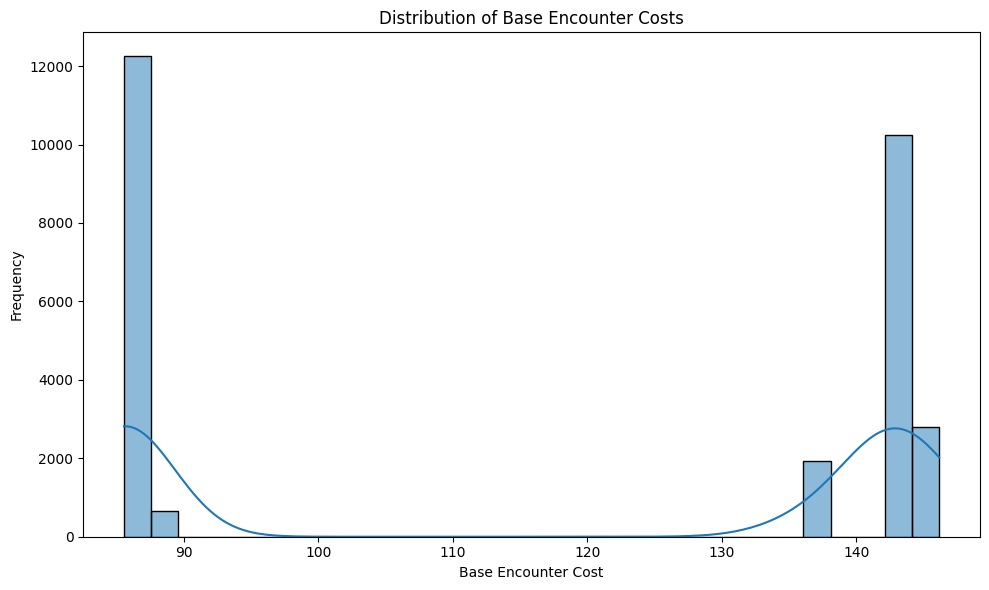

In [37]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=encounters,
    x='BASE_ENCOUNTER_COST',
    bins=30,
    kde=True
)

plt.title('Distribution of Base Encounter Costs')
plt.xlabel('Base Encounter Cost')
plt.ylabel('Frequency')

plt.tight_layout()

plt.savefig(
    'visualisations/01_Base_Encounter_Cost_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

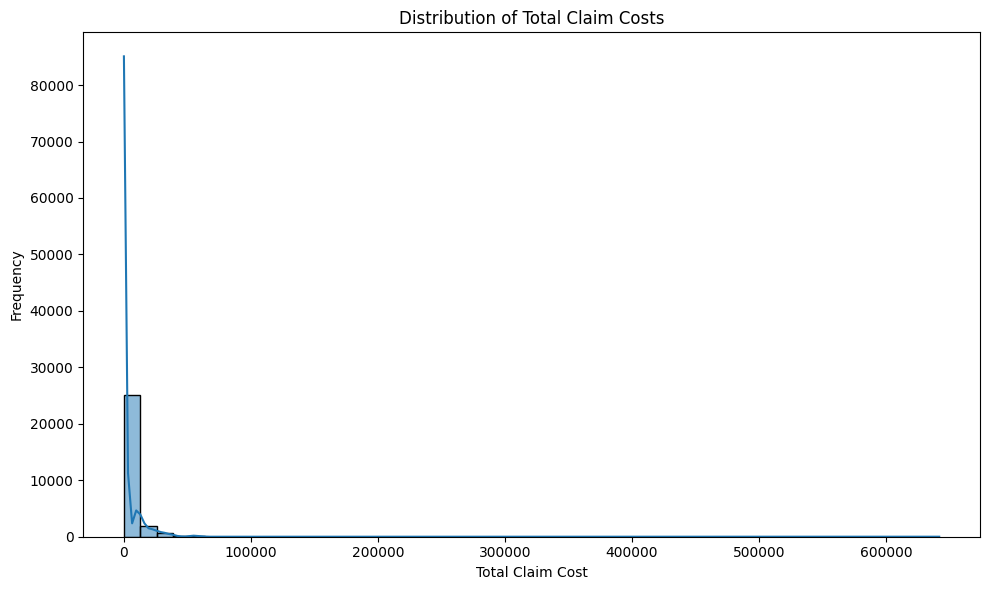

In [38]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=encounters,
    x='TOTAL_CLAIM_COST',
    bins=50,
    kde=True
)

plt.title('Distribution of Total Claim Costs')
plt.xlabel('Total Claim Cost')
plt.ylabel('Frequency')

plt.tight_layout()

plt.savefig(
    'visualisations/02_Total_Claim_Cost_Distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

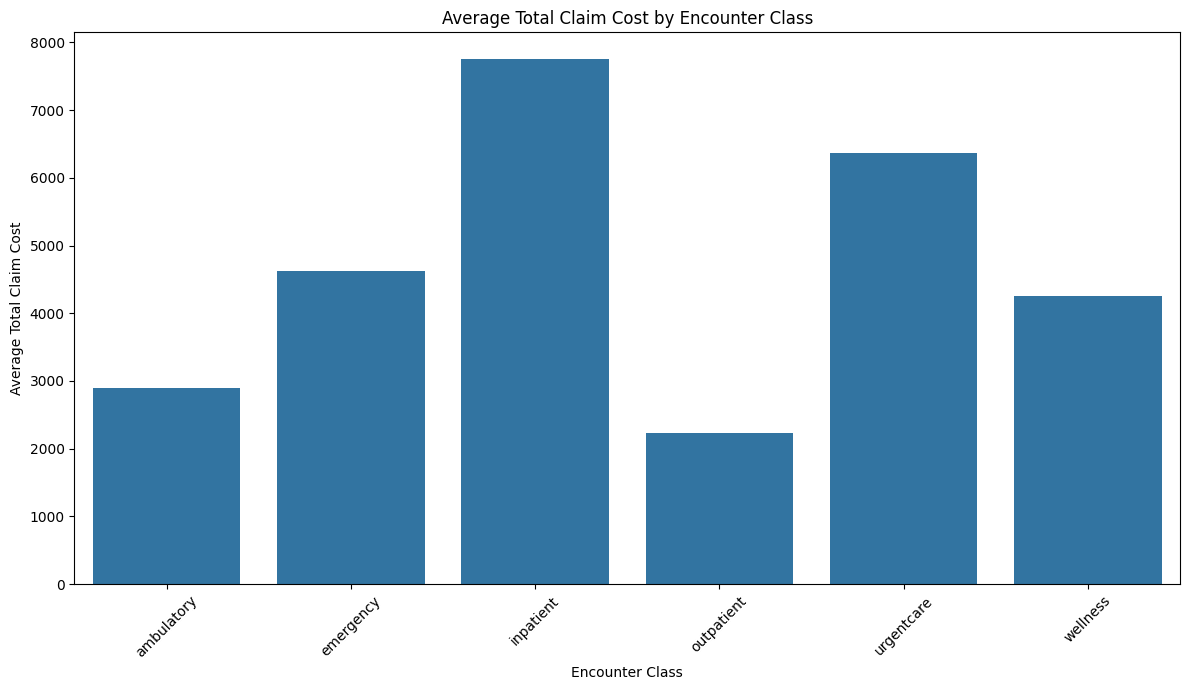

In [39]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=class_summary,
    x='ENCOUNTERCLASS',
    y='Average_Total_Claim_Cost'
)

plt.title('Average Total Claim Cost by Encounter Class')
plt.xlabel('Encounter Class')
plt.ylabel('Average Total Claim Cost')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    'visualisations/03_Average_Claim_Cost_by_Class.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

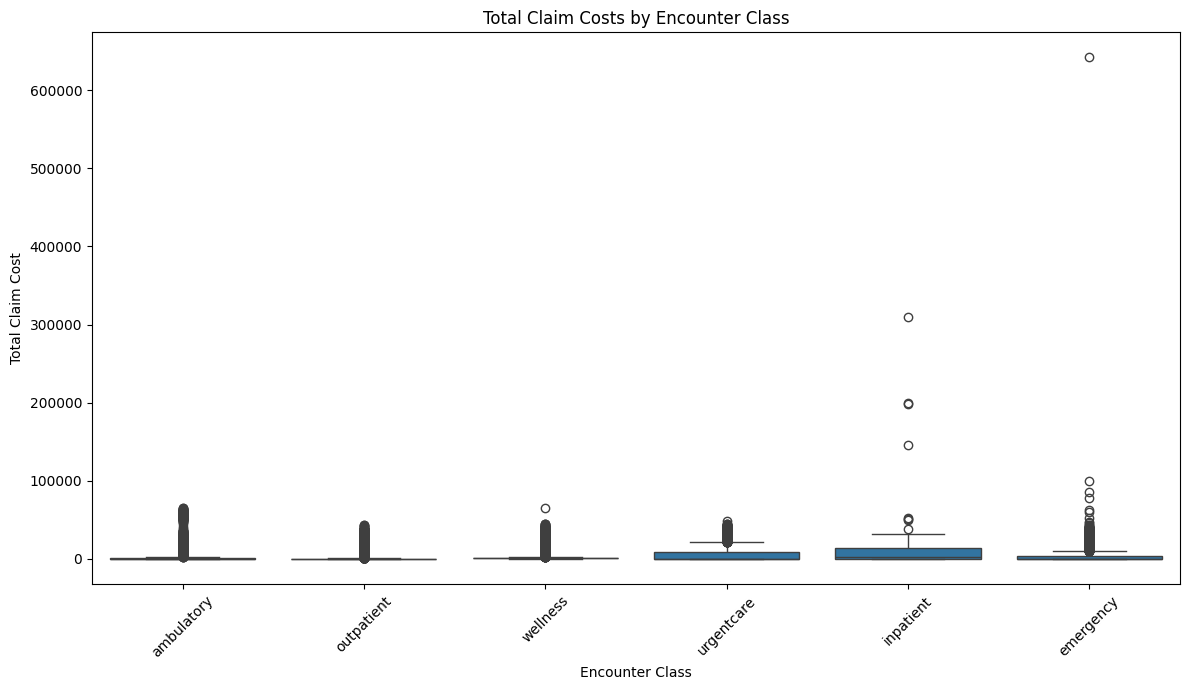

In [40]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=encounters,
    x='ENCOUNTERCLASS',
    y='TOTAL_CLAIM_COST'
)

plt.title('Total Claim Costs by Encounter Class')
plt.xlabel('Encounter Class')
plt.ylabel('Total Claim Cost')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    'visualisations/04_Claim_Cost_Boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

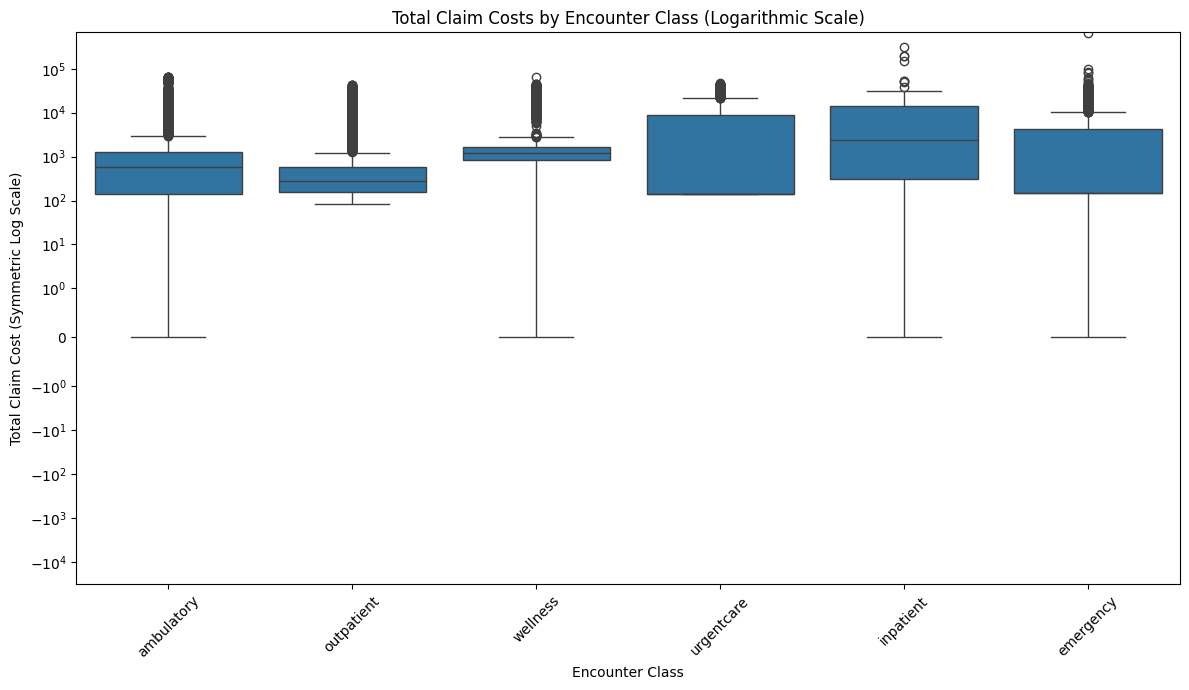

In [41]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=encounters,
    x='ENCOUNTERCLASS',
    y='TOTAL_CLAIM_COST'
)

plt.yscale('symlog', linthresh=1)

plt.title('Total Claim Costs by Encounter Class (Logarithmic Scale)')
plt.xlabel('Encounter Class')
plt.ylabel('Total Claim Cost (Symmetric Log Scale)')
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    'visualisations/05_Claim_Cost_Boxplot_Log_Scale.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [42]:
print(os.listdir('visualisations'))

['05_Claim_Cost_Boxplot_Log_Scale.png', '01_Base_Encounter_Cost_Distribution.png', '03_Average_Claim_Cost_by_Class.png', '04_Claim_Cost_Boxplot.png', '02_Total_Claim_Cost_Distribution.png']


In [43]:
import shutil

shutil.make_archive(
    'week3_visualisations',
    'zip',
    'visualisations'
)

print("All five graphs have been packaged successfully!")

All five graphs have been packaged successfully!


In [44]:
from google.colab import files

files.download('week3_visualisations.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
import shutil
import os

result_files = [
    'Encounter_Class_Descriptive_Statistics.csv',
    'Pairwise_Statistical_Tests.csv',
    'GEE_Main_Results.csv',
    'GEE_Model_Comparison.csv'
]

for file in result_files:
    print(file, "—", "Found" if os.path.exists(file) else "Missing")

Encounter_Class_Descriptive_Statistics.csv — Found
Pairwise_Statistical_Tests.csv — Found
GEE_Main_Results.csv — Found
GEE_Model_Comparison.csv — Found


In [46]:
import zipfile

with zipfile.ZipFile('week3_statistical_results.zip', 'w') as zipf:
    for file in result_files:
        zipf.write(file)

print("All four statistical results have been packaged successfully!")

All four statistical results have been packaged successfully!


In [47]:
from google.colab import files

files.download('week3_statistical_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>